# 06 · Geoestadística de la precipitación extrema

| | |
|---|---|
| **Pregunta** | ¿Con qué precisión puede reconstruirse el campo de lluvia de un evento extremo a partir de la red de estaciones que realmente existe en el norte, y dónde se concentra el error? |
| **Datos** | CHIRPS v2.0 mensual (0,05°, ≈ 5,5 km) de marzo de 1998, 2017 y 2023; coordenadas de 235 estaciones meteorológicas SENAMHI (red actual e histórica) dentro del ámbito; Copernicus DEM GLO-90 agregado a la grilla de CHIRPS; límites distritales INEI. |
| **Diseño** | Se observa el campo solo en los píxeles con estación (red real) y se interpola al resto. Como el campo completo es conocido, el error se mide en cada píxel y no solo en las estaciones. |
| **Métodos** | Semivariograma empírico (estimador de Matheron) y ajuste por mínimos cuadrados ponderados (Cressie, 1985); variogramas direccionales para anisotropía; interpolación por distancia inversa (IDW) como referencia; kriging ordinario y kriging con deriva externa de altitud (Goovaerts, 2000); validación cruzada dejando uno fuera y validación contra el campo completo; ratio de error cuadrático estandarizado (MSDR) para calibrar la varianza de kriging. |
| **Salidas** | `outputs/figuras/06_*.png` · `outputs/tablas/06_validacion_interpolacion.csv` · `data/processed/lluvia_extrema_distrito.csv`. |

**Sobre la fuente.** CHIRPS combina satélite con pluviómetros (incluidos los de SENAMHI) y es el producto de referencia
para lluvia mensual en zonas con red escasa (Funk et al., 2015). Aquí cumple el papel de *campo verdadero*: los valores
en las estaciones son los del píxel CHIRPS que las contiene, no el registro del pluviómetro. Lo que se evalúa es
cuánta información pierde la geometría de la red, que es la pregunta relevante para un mapa de exposición.

In [1]:
from pathlib import Path
import time
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import statsmodels.api as sm
from pykrige.ok import OrdinaryKriging
from pykrige.uk import UniversalKriging
from pyproj import Transformer
from rasterio.enums import Resampling
from rasterio.features import geometry_mask
from rasterio.merge import merge
from rasterio.warp import reproject
from rasterio.windows import from_bounds
from scipy.optimize import curve_fit
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist

warnings.filterwarnings("ignore")
t0 = time.time()

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
DATA = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figuras"
TAB = ROOT / "outputs" / "tablas"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
A_UTM = Transformer.from_crs(4326, 32717, always_xy=True)

## 1. Campo de referencia, relieve y red de estaciones

In [2]:
distritos = gpd.read_file(DATA / "geobanca_norte.gpkg", layer="distritos")
departamentos = distritos.dissolve("departamento").reset_index()
region = distritos.dissolve().geometry.iloc[0]
bounds = distritos.total_bounds + np.array([-0.1, -0.1, 0.1, 0.1])

def leer_chirps(ym):
    with rasterio.open(RAW / "chirps" / f"chirps-v2.0.{ym}.tif") as src:
        win = from_bounds(*bounds, transform=src.transform)
        arr = src.read(1, window=win).astype(float)
        tr = src.window_transform(win)
    arr[arr < 0] = np.nan
    return arr, tr

EVENTOS = {"1998-03": "El Niño extraordinario", "2017-03": "El Niño costero", "2023-03": "Ciclón Yaku"}
campos = {}
for ev in EVENTOS:
    campos[ev], TR = leer_chirps(ev.replace("-", "."))
FORMA = campos["1998-03"].shape
MASK = geometry_mask([region], out_shape=FORMA, transform=TR, invert=True)

# DEM de 90 m llevado a la grilla CHIRPS por promedio de área
teselas = [rasterio.open(f) for f in sorted((RAW / "dem").glob("*.tif"))]
dem, dem_tr = merge(teselas, bounds=tuple(bounds), res=(1 / 120, 1 / 120))
ALT = np.full(FORMA, np.nan)
reproject(dem[0].astype(float), ALT, src_transform=dem_tr, src_crs="EPSG:4326",
          dst_transform=TR, dst_crs="EPSG:4326", resampling=Resampling.average)
for t in teselas:
    t.close()

# Píxeles de la grilla en km (UTM 17S)
rr, cc = np.where(MASK)
lon_g, lat_g = rasterio.transform.xy(TR, rr, cc)
xg, yg = A_UTM.transform(np.array(lon_g), np.array(lat_g))
xg, yg = xg / 1000, yg / 1000
alt_g = ALT[rr, cc] / 1000
print(f"Píxeles en el ámbito: {MASK.sum():,} | altitud media {np.nanmean(alt_g)*1000:,.0f} m")

# Estaciones meteorológicas SENAMHI (red actual tipo M + catálogo histórico)
e1 = pd.read_csv(RAW / "senamhi" / "estaciones_red_actual.csv", dtype=str).query("tipo == 'M'")
e2 = pd.read_csv(RAW / "senamhi" / "estaciones_descarga_historica.csv", dtype=str)
est = (pd.concat([e1[["codigo", "nombre", "lat", "lon"]], e2[["codigo", "nombre", "lat", "lon"]]])
         .drop_duplicates("codigo").astype({"lat": float, "lon": float}))
est = gpd.GeoDataFrame(est, geometry=gpd.points_from_xy(est.lon, est.lat), crs=4326)
est = est[est.within(region)].copy()
est["r"], est["c"] = rasterio.transform.rowcol(TR, est.lon.values, est.lat.values)

# Varias estaciones caen en el mismo píxel: se colapsan (un dato por soporte)
red = (est.groupby(["r", "c"]).agg(lon=("lon", "mean"), lat=("lat", "mean"), n_est=("codigo", "size"))
          .reset_index())
red["x"], red["y"] = A_UTM.transform(red.lon.values, red.lat.values)
red["x"] /= 1000; red["y"] /= 1000
red["alt"] = ALT[red.r, red.c] / 1000
print(f"Estaciones en el ámbito: {len(est)} | píxeles distintos con estación: {len(red)}")

d_vecino, _ = cKDTree(red[["x", "y"]].values).query(np.c_[xg, yg])
print(f"Distancia del píxel a la estación más cercana: mediana {np.median(d_vecino):.1f} km, "
      f"p90 {np.percentile(d_vecino, 90):.1f} km, máx {d_vecino.max():.0f} km")

Píxeles en el ámbito: 3,695 | altitud media 1,351 m
Estaciones en el ámbito: 235 | píxeles distintos con estación: 149
Distancia del píxel a la estación más cercana: mediana 14.5 km, p90 42.4 km, máx 112 km


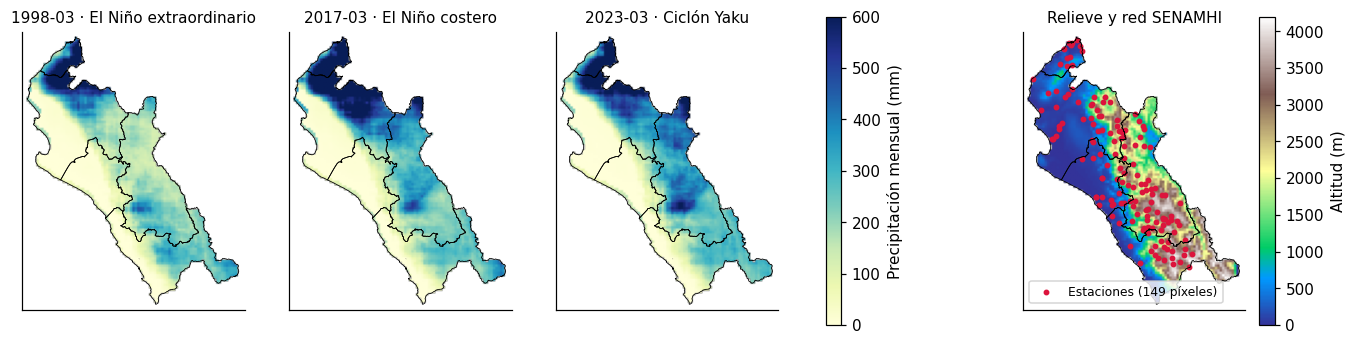

In [3]:
def a_imagen(v):
    img = np.full(FORMA, np.nan); img[rr, cc] = v; return img

EXT = [TR.c, TR.c + TR.a * FORMA[1], TR.f + TR.e * FORMA[0], TR.f]
def fondo(ax, titulo):
    departamentos.boundary.plot(ax=ax, color="k", lw=0.5)
    ax.set_title(titulo, fontsize=10); ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")

fig, axs = plt.subplots(1, 4, figsize=(15, 5.2))
for ax, ev in zip(axs[:3], EVENTOS):
    im = ax.imshow(np.where(MASK, campos[ev], np.nan), extent=EXT, cmap="YlGnBu", vmin=0, vmax=600)
    fondo(ax, f"{ev} · {EVENTOS[ev]}")
plt.colorbar(im, ax=axs[:3], shrink=0.7, label="Precipitación mensual (mm)")
im = axs[3].imshow(np.where(MASK, ALT, np.nan), extent=EXT, cmap="terrain", vmin=0, vmax=4200)
axs[3].scatter(red.lon, red.lat, s=8, c="crimson", label=f"Estaciones ({len(red)} píxeles)")
fondo(axs[3], "Relieve y red SENAMHI"); axs[3].legend(loc="lower left", fontsize=8)
plt.colorbar(im, ax=axs[3], shrink=0.7, label="Altitud (m)")
plt.savefig(FIG / "06_campos_y_red.png", bbox_inches="tight"); plt.show()

**Lectura.** Los tres eventos concentran la lluvia en Tumbes y en el nororiente de Piura, con más de 600 mm en el
mes en zonas que son semiáridas en un año normal; marzo de 2017 y de 2023 superan a marzo de 1998 (cuyo pico fue
en enero y febrero) y además marcan un núcleo en la sierra sur de Cajamarca. La red está densa en la sierra de
Cajamarca y en los valles costeros, y rala en el litoral de Sechura y Lambayeque y en el extremo oriental de La
Libertad, donde hay píxeles a más de 100 km de una estación. Esa geometría es la que se pone a prueba.

## 2. Semivariograma

La lluvia mensual es muy asimétrica (ceros en el desierto, cientos de milímetros en la sierra), por eso se modela
Z = log(1 + P). El semivariograma empírico usa el estimador de Matheron en clases de 20 km y los modelos esférico,
exponencial y gaussiano se ajustan por mínimos cuadrados ponderados con pesos N(h)/γ(h)², que priorizan las
distancias cortas, las que más pesan en la predicción.

In [4]:
CLASES = np.arange(0, 260, 20)

def esferico(h, c0, c, a):  return np.where(h < a, c0 + c * (1.5 * h / a - 0.5 * (h / a) ** 3), c0 + c)
def exponencial(h, c0, c, a): return c0 + c * (1 - np.exp(-3 * h / a))
def gaussiano(h, c0, c, a):  return c0 + c * (1 - np.exp(-3 * (h / a) ** 2))
MODELOS = {"Esférico": esferico, "Exponencial": exponencial, "Gaussiano": gaussiano}

def variograma_empirico(x, y, v, angulo=None, tol=22.5):
    pares = np.c_[x, y]
    D = pdist(pares); G = 0.5 * pdist(v[:, None]) ** 2
    if angulo is not None:
        i, j = np.triu_indices(len(x), 1)
        az = np.degrees(np.arctan2(x[j] - x[i], y[j] - y[i])) % 180
        dif = np.abs((az - angulo + 90) % 180 - 90)
        D, G = D[dif <= tol], G[dif <= tol]
    k = np.digitize(D, CLASES); h, g, n = [], [], []
    for b in range(1, len(CLASES)):
        s = k == b
        if s.sum() >= 20:
            h.append(D[s].mean()); g.append(G[s].mean()); n.append(s.sum())
    return np.array(h), np.array(g), np.array(n)

def ajustar(h, g, n, f):
    p0 = [0.1, g.max(), 100]
    p, _ = curve_fit(f, h, g, p0=p0, bounds=([0, 0, 5], [5, 10, 1000]), sigma=f(h, *p0) / np.sqrt(n))
    wss = (n / f(h, *p) ** 2 * (g - f(h, *p)) ** 2).sum()
    return p, wss

red["z98"] = np.log1p(campos["1998-03"][red.r, red.c])
h, g, n = variograma_empirico(red.x.values, red.y.values, red.z98.values)
filas = []
for nom, f in MODELOS.items():
    p, wss = ajustar(h, g, n, f)
    filas.append({"modelo": nom, "pepita": p[0], "meseta_parcial": p[1], "rango_km": p[2], "WSS": wss})
ajustes = pd.DataFrame(filas).set_index("modelo")
ajustes.round(3)

,pepita,meseta_parcial,rango_km,WSS
modelo,,,,
Esférico,0.000,2.639,176.780,115.748
Exponencial,0.000,3.252,330.643,217.946
Gaussiano,0.236,2.440,147.131,46.347


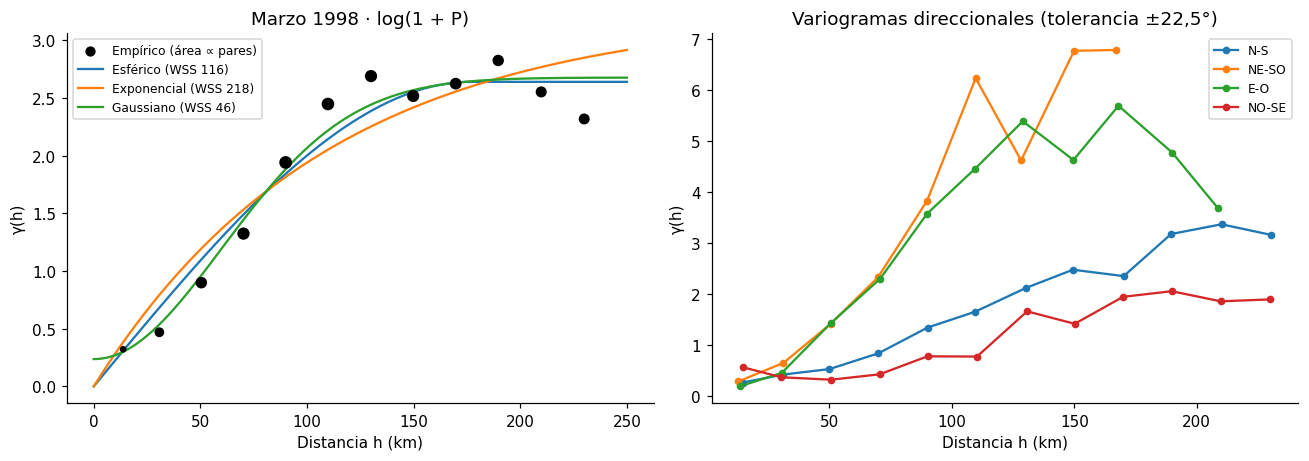

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axs[0]
ax.scatter(h, g, s=n / 15, c="k", zorder=3, label="Empírico (área ∝ pares)")
hh = np.linspace(0, 250, 300)
for nom, f in MODELOS.items():
    ax.plot(hh, f(hh, *ajustes.loc[nom, ["pepita", "meseta_parcial", "rango_km"]]),
            label=f"{nom} (WSS {ajustes.loc[nom, 'WSS']:.0f})")
ax.set(xlabel="Distancia h (km)", ylabel="γ(h)", title="Marzo 1998 · log(1 + P)"); ax.legend(fontsize=8)

ax = axs[1]
for ang, nom in [(0, "N-S"), (45, "NE-SO"), (90, "E-O"), (135, "NO-SE")]:
    hd, gd, nd = variograma_empirico(red.x.values, red.y.values, red.z98.values, angulo=ang)
    ax.plot(hd, gd, "o-", ms=4, label=nom)
ax.set(xlabel="Distancia h (km)", ylabel="γ(h)", title="Variogramas direccionales (tolerancia ±22,5°)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "06_semivariograma.png", bbox_inches="tight"); plt.show()

**Lectura.** El modelo gaussiano tiene el menor error ponderado: el campo es suave a escala de decenas de
kilómetros, con pepita pequeña (0,24 frente a una meseta de 2,7) y rango práctico cercano a 150 km, la escala de
los sistemas de lluvia de El Niño. Los variogramas direccionales muestran **anisotropía marcada**: en dirección
NE-SO y E-O (perpendicular a la costa) la semivarianza a 90-110 km es entre cinco y siete veces la de la dirección NO-SE (paralela a la
costa). El campo cambia rápido de la costa hacia la sierra y lento a lo largo de ella; la altitud como deriva
externa es la forma natural de capturar ese gradiente.

## 3. Interpoladores

* **IDW** (potencia 2): referencia determinista sin modelo de dependencia.
* **Kriging ordinario (KO):** media local desconocida y variograma gaussiano ajustado arriba.
* **Kriging con deriva externa (KDE):** la media depende linealmente de la altitud del DEM, disponible en cada
  píxel. El variograma se reajusta sobre los residuos de la deriva (Hengl, Heuvelink y Rossiter, 2007).

La selección de la deriva se hizo solo con validación cruzada en las estaciones (sección 4): agregar la altitud al
cuadrado o las coordenadas mejora poco dentro de la red y extrapola mal fuera de ella.

In [6]:
def gauss_pk(p, h):            # firma que espera pykrige para variogramas propios
    return gaussiano(h, *p)

def ajustar_variograma(x, y, v):
    hh, gg, nn = variograma_empirico(x, y, v)
    return ajustar(hh, gg, nn, gaussiano)[0]

def idw(xt, yt, xs, ys, zs, pot=2):
    d = np.hypot(xt[:, None] - xs, yt[:, None] - ys) + 1e-6
    w = d ** -pot
    return (w * zs).sum(1) / w.sum(1), None

def ko(xt, yt, xs, ys, zs, p):
    m = OrdinaryKriging(xs, ys, zs, variogram_model="custom", variogram_parameters=list(p),
                        variogram_function=gauss_pk)
    z, s2 = m.execute("points", xt, yt)
    return np.asarray(z), np.asarray(s2)

def kde(xt, yt, at, xs, ys, as_, zs, p):
    m = UniversalKriging(xs, ys, zs, variogram_model="custom", variogram_parameters=list(p),
                         variogram_function=gauss_pk, drift_terms=["specified"], specified_drift=[as_])
    z, s2 = m.execute("points", xt, yt, specified_drift_arrays=[at])
    return np.asarray(z), np.asarray(s2)

def evaluar_evento(ev):
    campo = campos[ev]
    z = np.log1p(campo[red.r, red.c]); x, y, a = red.x.values, red.y.values, red.alt.values
    p_ko = ajustar_variograma(x, y, z)
    res = sm.OLS(z, sm.add_constant(a)).fit()
    p_kde = ajustar_variograma(x, y, res.resid)
    # Validación cruzada dejando uno fuera (variograma fijo, práctica estándar)
    loo = {"IDW": np.empty(len(z)), "KO": np.empty(len(z)), "KDE": np.empty(len(z))}
    var = {"KO": np.empty(len(z)), "KDE": np.empty(len(z))}
    for i in range(len(z)):
        s = np.arange(len(z)) != i
        loo["IDW"][i] = idw(x[[i]], y[[i]], x[s], y[s], z[s])[0][0]
        zk, vk = ko(x[[i]], y[[i]], x[s], y[s], z[s], p_ko); loo["KO"][i], var["KO"][i] = zk[0], vk[0]
        zk, vk = kde(x[[i]], y[[i]], a[[i]], x[s], y[s], a[s], z[s], p_kde); loo["KDE"][i], var["KDE"][i] = zk[0], vk[0]
    # Predicción sobre todo el campo
    grid = {"IDW": idw(xg, yg, x, y, z), "KO": ko(xg, yg, x, y, z, p_ko),
            "KDE": kde(xg, yg, alt_g, x, y, a, z, p_kde)}
    verdad = campo[rr, cc]
    filas = []
    for m in loo:
        e_loo = np.expm1(loo[m]) - np.expm1(z)
        e_g = np.expm1(grid[m][0]) - verdad
        filas.append({"evento": ev, "metodo": m,
                      "RMSE_LOO_mm": np.sqrt(np.mean(e_loo ** 2)), "MAE_LOO_mm": np.mean(np.abs(e_loo)),
                      "MSDR_LOO": np.mean((loo[m] - z) ** 2 / var[m]) if m in var else np.nan,
                      "RMSE_campo_mm": np.sqrt(np.mean(e_g ** 2)), "MAE_campo_mm": np.mean(np.abs(e_g)),
                      "sesgo_campo_mm": np.mean(e_g), "r_campo": np.corrcoef(np.expm1(grid[m][0]), verdad)[0, 1]})
    return pd.DataFrame(filas), grid, loo, z, p_ko, p_kde, res

resultados = {ev: evaluar_evento(ev) for ev in EVENTOS}
validacion = pd.concat([r[0] for r in resultados.values()], ignore_index=True)
validacion.to_csv(TAB / "06_validacion_interpolacion.csv", index=False)
print(f"Tiempo acumulado: {time.time() - t0:.0f} s")
validacion.round(2)

Tiempo acumulado: 34 s


,evento,metodo,RMSE_LOO_mm,MAE_LOO_mm,MSDR_LOO,RMSE_campo_mm,MAE_campo_mm,sesgo_campo_mm,r_campo
0,1998-03,IDW,94.68,56.40,NaN,101.01,57.94,-20.07,0.86
1,1998-03,KO,72.54,50.52,1.61,74.86,48.24,-13.59,0.91
2,1998-03,KDE,74.78,51.66,1.42,74.07,50.72,-17.08,0.91
3,2017-03,IDW,136.91,78.94,NaN,155.01,83.91,-39.36,0.88
4,2017-03,KO,95.25,60.68,1.67,98.23,59.46,-13.62,0.94
5,2017-03,KDE,98.57,64.39,1.50,96.58,62.72,-17.24,0.94
6,2023-03,IDW,111.10,72.51,NaN,115.07,73.49,-34.64,0.89
7,2023-03,KO,94.09,62.86,1.64,86.00,56.14,-13.68,0.92
8,2023-03,KDE,94.88,65.53,1.47,84.77,58.86,-16.12,0.92


In [7]:
_, grid98, loo98, z98, p_ko98, p_kde98, res98 = resultados["1998-03"]
print("Variograma KO  (pepita, meseta parcial, rango km):", np.round(p_ko98, 3))
print("Variograma KDE sobre residuos                     :", np.round(p_kde98, 3))
print(f"Deriva KDE: log(1+P) = {res98.params[0]:.2f} + {res98.params[1]:.2f}·altitud(km)  "
      f"(R² = {res98.rsquared:.2f})")
resumen = validacion.groupby("metodo")[["RMSE_LOO_mm", "RMSE_campo_mm", "r_campo"]].mean()
resumen.round(2)

Variograma KO  (pepita, meseta parcial, rango km): [  0.236   2.44  147.131]
Variograma KDE sobre residuos                     : [  0.303   1.667 157.396]
Deriva KDE: log(1+P) = 4.24 + 0.47·altitud(km)  (R² = 0.16)


,RMSE_LOO_mm,RMSE_campo_mm,r_campo
metodo,,,
IDW,114.23,123.70,0.88
KDE,89.41,85.14,0.93
KO,87.29,86.36,0.92


## 4. Mapas de predicción e incertidumbre (marzo de 1998)

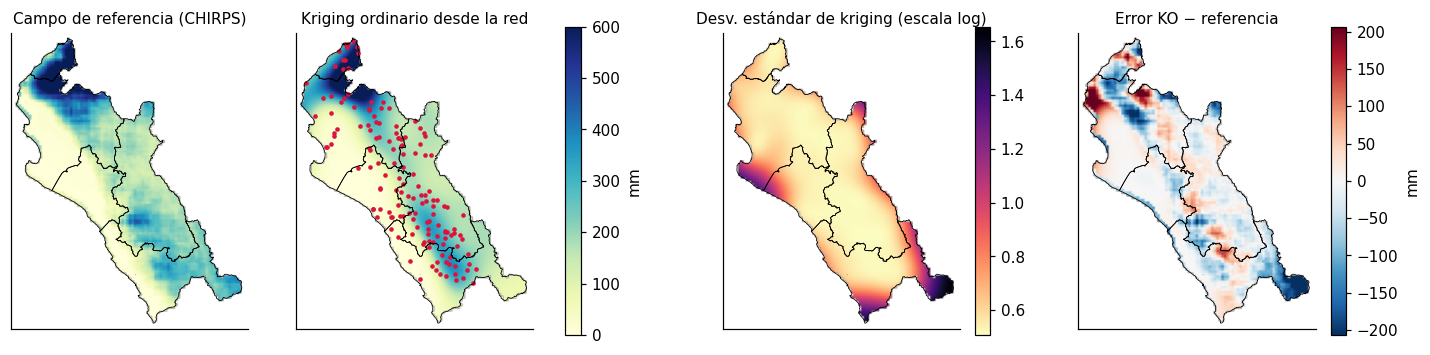

In [8]:
verdad98 = campos["1998-03"][rr, cc]
pred_ko = np.expm1(grid98["KO"][0]); sd_ko = np.sqrt(grid98["KO"][1])
err_ko = pred_ko - verdad98

fig, axs = plt.subplots(1, 4, figsize=(16, 5.2))
im = axs[0].imshow(a_imagen(verdad98), extent=EXT, cmap="YlGnBu", vmin=0, vmax=600); fondo(axs[0], "Campo de referencia (CHIRPS)")
axs[1].imshow(a_imagen(pred_ko), extent=EXT, cmap="YlGnBu", vmin=0, vmax=600); fondo(axs[1], "Kriging ordinario desde la red")
axs[1].scatter(red.lon, red.lat, s=4, c="crimson")
plt.colorbar(im, ax=axs[:2], shrink=0.7, label="mm")
im = axs[2].imshow(a_imagen(sd_ko), extent=EXT, cmap="magma_r"); fondo(axs[2], "Desv. estándar de kriging (escala log)")
plt.colorbar(im, ax=axs[2], shrink=0.7)
lim = np.nanpercentile(np.abs(err_ko), 97)
im = axs[3].imshow(a_imagen(err_ko), extent=EXT, cmap="RdBu_r", vmin=-lim, vmax=lim); fondo(axs[3], "Error KO − referencia")
plt.colorbar(im, ax=axs[3], shrink=0.7, label="mm")
plt.savefig(FIG / "06_kriging_1998.png", bbox_inches="tight"); plt.show()

## 5. ¿Dónde falla la red?

Correlación de Spearman entre la desv. estándar de kriging y el error absoluto real: 0.35


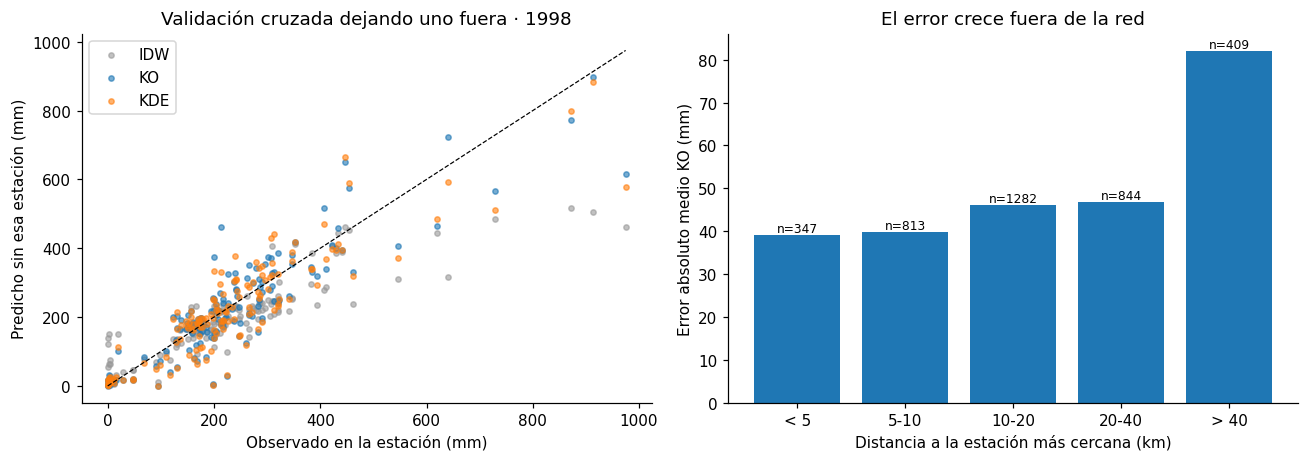

,pixeles,MAE_mm,sd_kriging
tramo,,,
< 5,347,39.11,0.53
5-10,813,39.88,0.54
10-20,1282,46.15,0.56
20-40,844,46.88,0.67
> 40,409,81.98,1.15


In [9]:
tramos = pd.cut(d_vecino, [0, 5, 10, 20, 40, 200], labels=["< 5", "5-10", "10-20", "20-40", "> 40"])
por_dist = (pd.DataFrame({"tramo": tramos, "abs_err": np.abs(err_ko), "sd": sd_ko})
              .groupby("tramo", observed=True).agg(pixeles=("abs_err", "size"), MAE_mm=("abs_err", "mean"),
                                                   sd_kriging=("sd", "mean")))
rho_sd = pd.Series(sd_ko).corr(pd.Series(np.abs(np.log1p(pred_ko) - np.log1p(verdad98))), method="spearman")
print(f"Correlación de Spearman entre la desv. estándar de kriging y el error absoluto real: {rho_sd:.2f}")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))
for m, col in [("IDW", "0.6"), ("KO", "C0"), ("KDE", "C1")]:
    axs[0].scatter(np.expm1(z98), np.expm1(loo98[m]), s=12, alpha=0.6, color=col, label=m)
mx = np.expm1(z98).max(); axs[0].plot([0, mx], [0, mx], "k--", lw=0.8)
axs[0].set(xlabel="Observado en la estación (mm)", ylabel="Predicho sin esa estación (mm)",
           title="Validación cruzada dejando uno fuera · 1998"); axs[0].legend()
axs[1].bar(por_dist.index.astype(str), por_dist.MAE_mm, color="C0")
for i, v in enumerate(por_dist.pixeles): axs[1].text(i, por_dist.MAE_mm.iloc[i], f"n={v}", ha="center", va="bottom", fontsize=8)
axs[1].set(xlabel="Distancia a la estación más cercana (km)", ylabel="Error absoluto medio KO (mm)",
           title="El error crece fuera de la red")
plt.tight_layout(); plt.savefig(FIG / "06_validacion.png", bbox_inches="tight"); plt.show()
por_dist.round(2)

## 6. Exposición distrital a lluvia extrema

Para el score del notebook 09 se usa el **campo de referencia** (es la mejor estimación disponible en cada píxel) y
se agrega por distrito como el promedio de los píxeles cuyo centro cae dentro. Los distritos más pequeños que un
píxel toman el valor del píxel de su centroide. El índice de exposición promedia los puntajes z de los tres eventos,
de modo que pesa igual un distrito golpeado por los tres que uno golpeado por uno solo con intensidad extrema.
Se exporta también la desviación estándar de kriging de 1998 como indicador de cuán observada está la zona.

In [10]:
pix = gpd.GeoDataFrame({"i": np.arange(len(rr))}, geometry=gpd.points_from_xy(lon_g, lat_g), crs=4326)
for ev in EVENTOS:
    pix[f"pp_{ev[:4]}"] = campos[ev][rr, cc]
pix["sd_kriging_1998"] = sd_ko
cols = [c for c in pix.columns if c.startswith(("pp_", "sd_"))]
zonal = gpd.sjoin(pix, distritos[["ubigeo", "geometry"]], predicate="within").groupby("ubigeo")[cols].mean()

faltan = distritos[~distritos.ubigeo.isin(zonal.index)]
cent = faltan.to_crs(32717).geometry.centroid.to_crs(4326)
fr, fc = rasterio.transform.rowcol(TR, cent.x.values, cent.y.values)
relleno = pd.DataFrame({f"pp_{ev[:4]}": campos[ev][fr, fc] for ev in EVENTOS}, index=faltan.ubigeo)
_, idx = cKDTree(np.c_[lon_g, lat_g]).query(np.c_[cent.x, cent.y])
relleno["sd_kriging_1998"] = sd_ko[idx]
lluvia = pd.concat([zonal, relleno]).rename_axis("ubigeo").reset_index()
lluvia["fuente_valor"] = np.where(lluvia.ubigeo.isin(zonal.index), "promedio_pixeles", "pixel_centroide")

zs = [(lluvia[c] - lluvia[c].mean()) / lluvia[c].std() for c in lluvia.columns if c.startswith("pp_")]
lluvia["indice_exposicion"] = np.mean(zs, axis=0)
lluvia = lluvia.merge(distritos[["ubigeo", "distrito", "provincia", "departamento"]], on="ubigeo")
lluvia.to_csv(DATA / "lluvia_extrema_distrito.csv", index=False)
print(f"Distritos: {len(lluvia)} ({(lluvia.fuente_valor == 'pixel_centroide').sum()} por píxel del centroide)")
print(f"Tiempo total: {time.time() - t0:.0f} s")
lluvia.nlargest(10, "indice_exposicion")[["distrito", "provincia", "departamento", "pp_1998", "pp_2017",
                                          "pp_2023", "indice_exposicion"]].round(2)

Distritos: 327 (12 por píxel del centroide)
Tiempo total: 39 s


,distrito,provincia,departamento,pp_1998,pp_2017,pp_2023,indice_exposicion
313,MATAPALO,ZARUMILLA,TUMBES,851.56,1362.00,1133.92,4.95
305,PAMPAS DE HOSPITAL,TUMBES,TUMBES,700.35,1221.08,911.99,3.96
309,CASITAS,CONTRALMIRANTE VILLAR,TUMBES,685.39,1112.49,751.51,3.46
314,PAPAYAL,ZARUMILLA,TUMBES,695.98,977.26,830.63,3.42
288,LANCONES,SULLANA,PIURA,698.59,1101.30,718.73,3.41
307,SAN JUAN DE LA VIRGEN,TUMBES,TUMBES,654.12,1016.80,831.66,3.38
306,SAN JACINTO,TUMBES,TUMBES,668.99,1081.28,744.65,3.36
261,SUYO,AYABACA,PIURA,609.95,952.68,708.83,2.95
312,AGUAS VERDES,ZARUMILLA,TUMBES,609.04,849.37,670.92,2.72
254,JILILI,AYABACA,PIURA,571.88,814.16,649.11,2.53


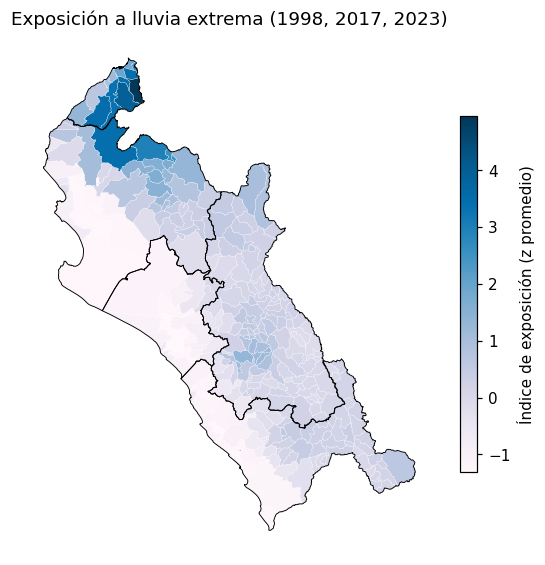

In [11]:
mapa = distritos.merge(lluvia[["ubigeo", "indice_exposicion"]], on="ubigeo")
fig, ax = plt.subplots(figsize=(6, 7))
mapa.plot("indice_exposicion", ax=ax, cmap="PuBu", legend=True, edgecolor="white", linewidth=0.15,
          legend_kwds={"shrink": 0.6, "label": "Índice de exposición (z promedio)"})
departamentos.boundary.plot(ax=ax, color="k", lw=0.6)
ax.set_axis_off(); ax.set_title("Exposición a lluvia extrema (1998, 2017, 2023)")
plt.savefig(FIG / "06_exposicion_distrital.png", bbox_inches="tight"); plt.show()

## Hallazgos

1. **Estructura espacial clara.** El log de la lluvia de marzo de 1998 tiene un semivariograma gaussiano con pepita
   pequeña (0,24) y rango práctico de 147 km, con anisotropía costa-sierra: a unos 100 km, la variación perpendicular a la costa es varias
   veces la paralela.
2. **El kriging supera a la interpolación determinista.** Promediando los tres eventos, el kriging ordinario reduce
   el RMSE frente a IDW de 114 a 87 mm en validación cruzada y de 124 a 86 mm sobre el campo completo; IDW además
   subestima en promedio entre 20 y 39 mm por suavizar los máximos.
3. **La altitud como deriva no mejora la predicción, pero sí la incertidumbre.** El kriging con deriva externa
   empata con el ordinario en error (85 frente a 86 mm sobre el campo) porque la relación lluvia-altitud es débil en
   eventos de El Niño (R² = 0,16), cuando llueve más en la costa que en la sierra. Su varianza está mejor calibrada:
   MSDR de 1,4 a 1,5 frente a 1,6 a 1,7 del ordinario (el valor ideal es 1).
4. **Ambos krigings son optimistas sobre su propio error.** Un MSDR mayor que 1 indica que la varianza de kriging
   subestima el error real; la desviación estándar de kriging ordena bien las zonas de riesgo (Spearman 0,35 con el
   error real), pero no debe leerse como un intervalo literal.
5. **El error depende de la distancia a la red.** El error absoluto medio es de unos 40 mm a menos de 10 km de una
   estación y sube a 82 mm a más de 40 km (409 píxeles, 11% del ámbito). La validación cruzada en estaciones
   (87 mm) coincide con la del campo completo (86 mm) solo en promedio: oculta que el error se concentra donde no
   hay estaciones.
6. **Exposición distrital.** `data/processed/lluvia_extrema_distrito.csv` resume los tres eventos por distrito. Los
   más expuestos están en Tumbes (Matapalo, Pampas de Hospital, Casitas, Papayal) y en la sierra de Piura
   (Lancones, Suyo, Jililí). Este índice es el componente de **riesgo climático** del score del notebook 09.

## Referencias

* Cressie, N. (1985). Fitting variogram models by weighted least squares. *Mathematical Geology, 17*(5), 563-586.
* Funk, C., et al. (2015). The climate hazards infrared precipitation with stations: A new environmental record for monitoring extremes. *Scientific Data, 2*, 150066.
* Goovaerts, P. (2000). Geostatistical approaches for incorporating elevation into the spatial interpolation of rainfall. *Journal of Hydrology, 228*(1-2), 113-129.
* Hengl, T., Heuvelink, G. B. M., & Rossiter, D. G. (2007). About regression-kriging: From equations to case studies. *Computers & Geosciences, 33*(10), 1301-1315.
* Matheron, G. (1963). Principles of geostatistics. *Economic Geology, 58*(8), 1246-1266.